In [4]:
!apt-get -qq install -y swig libboost-all-dev
!pip install -q rdkit==2026.3.6 vina==1.2.7 meeko==0.8.0 prody gemmi pdb2pqr

Software and Tools Guide, section 3.2 "Google Colab (Required)", step 4.

*** NOT IN COURSE *** The apt-get line is mine. Without it the vina wheel
failed to build on Colab on 2026-11-01 with "Failed to build 'vina'".

In [5]:
from google.colab import drive
drive.mount("/content/drive")
WORK = "/content/drive/MyDrive/as410662_project"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Software and Tools Guide, section 3.2 "Google Colab (Required)", step 6
("Everything in /content disappears when the session ends. Save inputs and
results to Google Drive").

In [6]:
import sys, platform, datetime, random
import numpy as np
from importlib.metadata import version

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
print("run date :", datetime.date.today().isoformat())
print("python   :", sys.version.split()[0], "on", platform.system())
for pkg in ["rdkit", "vina", "meeko", "numpy", "pandas", "gemmi","pdb2pqr", "propka"]:
    print(f"{pkg:9s}:", version(pkg))
print("seed     :", SEED)

run date : 2026-11-22
python   : 3.13.18 on Linux
rdkit    : 2026.3.6
vina     : 1.2.7
meeko    : 0.8.0
numpy    : 2.4.6
pandas   : 2.2.3
gemmi    : 0.7.5
pdb2pqr  : 3.8.0
propka   : 3.5.1
seed     : 2026


Software and Tools Guide, section 3.2 "Google Colab (Required)", step 7
("Put a provenance cell near the top. It is graded in the project").

In [7]:
from rdkit import Chem
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")

SDF_PATH = f"{WORK}/approved_chembl37.sdf"

APPROVED = []
n_records = 0
n_unparsed = 0
for mol in Chem.SDMolSupplier(SDF_PATH):
    n_records += 1
    if mol is None:
        n_unparsed += 1
        continue
    APPROVED.append({"name": mol.GetProp("chembl_pref_name"),
                     "chembl_id": mol.GetProp("chembl_id"),
                     "smiles": Chem.MolToSmiles(mol)})

print("records in SDF            :", n_records)
print("records RDKit could parse :", len(APPROVED))
print("records dropped, unparsed :", n_unparsed)

records in SDF            : 3311
records RDKit could parse : 3311
records dropped, unparsed : 0


Loads my starting library: the 3,311 FDA-approved drugs from the ChEMBL 37
export. Every record keeps its name, ChEMBL ID and SMILES so I can trace any
compound back later.

*** NOT IN COURSE *** The Guide and M01-M11 always start from a SMILES list
typed into the notebook. Reading an SDF file is not covered anywhere, so this
cell is mine. I used AI to help me find a way to read this gianr file since I did not think typing it all was feasable.

PROMPT USED: "How do I read an SDF file in RDKit and pull out a property field
and the SMILES for each molecule, skipping any the parser can't read?"

In [8]:
from rdkit.Chem.MolStandardize import rdMolStandardize

chooser = rdMolStandardize.LargestFragmentChooser()

APPROVED_STRIPPED = []
n_stripped = 0
for d in APPROVED:
    mol = Chem.MolFromSmiles(d["smiles"])
    if "." in d["smiles"]:
        mol = chooser.choose(mol)
        n_stripped += 1
    APPROVED_STRIPPED.append({"name": d["name"], "chembl_id": d["chembl_id"],
                              "smiles": Chem.MolToSmiles(mol)})

print("compounds in           :", len(APPROVED))
print("compounds out          :", len(APPROVED_STRIPPED))
print("had a salt stripped off:", n_stripped)

compounds in           : 3311
compounds out          : 3311
had a salt stripped off: 1163


a lot of entries are a drug plus a salt, so I keep the biggest
piece. Dropping them instead would lose 266 of my 630 acid-containing drugs,
which is the exact chemotype this screen is about.

*USED AI** PROMPT: "I have a list of
molecules in RDKit and some are salts, with a '.' in the SMILES. How do I keep
just the biggest piece of each one, using RDKit's built-in tool?"

In [9]:
seen = set()
APPROVED_UNIQUE = []
for d in APPROVED_STRIPPED:
    key = Chem.MolToInchiKey(Chem.MolFromSmiles(d["smiles"]))
    if key in seen:
        continue
    seen.add(key)
    APPROVED_UNIQUE.append(d)

print("compounds in :", len(APPROVED_STRIPPED))
print("compounds out:", len(APPROVED_UNIQUE))
print("duplicates   :", len(APPROVED_STRIPPED) - len(APPROVED_UNIQUE))

compounds in : 3311
compounds out: 2403
duplicates   : 908


USED AI: PROMPT: "I have a list of dicts in RDKit and some are the same
molecule twice. How do I keep only the first copy of each, using the InChIKey?"

In [10]:
import json
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen, rdMolDescriptors
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")

def profile(smi):
    m = Chem.MolFromSmiles(smi)
    if m is None:
        return None
    return {"mw": Descriptors.MolWt(m), "clogp": Crippen.MolLogP(m),
            "hbd": rdMolDescriptors.CalcNumHBD(m), "hba": rdMolDescriptors.CalcNumHBA(m),
            "tpsa": rdMolDescriptors.CalcTPSA(m),
            "rotb": rdMolDescriptors.CalcNumRotatableBonds(m),
            "scaffold": MurckoScaffold.MurckoScaffoldSmiles(mol=m)}

rows = []
for d in APPROVED_UNIQUE:
    p = profile(d["smiles"])
    if p:
        p["name"] = d["name"]
        p["smiles"] = d["smiles"]
        p["chembl_id"] = d["chembl_id"]
        rows.append(p)
print("profiled", len(rows), "compounds")

def ro5_violations(p):
    return sum([p["mw"] > 500, p["clogp"] > 5, p["hbd"] > 5, p["hba"] > 10])

def veber_pass(p):
    return p["rotb"] <= 10 and p["tpsa"] <= 140

fails_ro5 = [r for r in rows if ro5_violations(r) >= 2]
fails_veber = [r for r in rows if not veber_pass(r)]
print()
print("{} of {} fail Lipinski (2+ violations)".format(len(fails_ro5), len(rows)))
print("{} of {} fail Veber".format(len(fails_veber), len(rows)))
print()
for r in fails_ro5[:6]:
    print("  {:<20} MW {:>6.1f}  cLogP {:>5.2f}  HBD {:>2}  HBA {:>2}".format(
        r["name"], r["mw"], r["clogp"], r["hbd"], r["hba"]))

profiled 2403 compounds

256 of 2403 fail Lipinski (2+ violations)
458 of 2403 fail Veber

  PENTAGASTRIN         MW  767.9  cLogP  1.52  HBD  8  HBA  9
  EVANS BLUE           MW  868.9  cLogP  5.30  HBD  4  HBA 20
  IODOXAMATE MEGLUMINE MW 1287.9  cLogP  6.13  HBD  4  HBA  8
  MONENSIN SODIUM      MW  669.9  cLogP  2.94  HBD  3  HBA 11
  CALCIUM GLUBIONATE   MW  357.3  cLogP -7.00  HBD  8  HBA 12
  ROSE BENGAL SODIUM I 131 MW  979.7  cLogP  7.03  HBD  0  HBA  5


works out MW, cLogP, HBD, HBA, TPSA, rotatable bonds and the
Murcko scaffold for every compound. Nothing is filtered yet.

SOURCE: M09, the code cell under section 1.

In [11]:
def cost(rows, keep):
    kept = [r for r in rows if keep(r)]
    return (len(rows), len(kept),
            len({r["scaffold"] for r in rows}), len({r["scaffold"] for r in kept}))

for label, keep in [("Lipinski, at most 1 violation", lambda r: ro5_violations(r) <= 1),
                    ("Lipinski, zero violations", lambda r: ro5_violations(r) == 0),
                    ("Veber", veber_pass),
                    ("both", lambda r: ro5_violations(r) <= 1 and veber_pass(r))]:
    n, k, ns, ks = cost(rows, keep)
    print("{:<32} compounds {:>3}/{:<3} ({:>5.1f}%)   scaffolds {:>3}/{:<3} ({:>5.1f}%)".format(
        label, k, n, 100.0 * k / n, ks, ns, 100.0 * ks / ns))
print()
print("Compare the two percentages on each row. When the scaffold loss is worse")
print("than the compound loss, the filter is removing diversity, not just bulk.")

Lipinski, at most 1 violation    compounds 2147/2403 ( 89.3%)   scaffolds 1094/1249 ( 87.6%)
Lipinski, zero violations        compounds 1795/2403 ( 74.7%)   scaffolds 904/1249 ( 72.4%)
Veber                            compounds 1945/2403 ( 80.9%)   scaffolds 1037/1249 ( 83.0%)
both                             compounds 1886/2403 ( 78.5%)   scaffolds 989/1249 ( 79.2%)

Compare the two percentages on each row. When the scaffold loss is worse
than the compound loss, the filter is removing diversity, not just bulk.


this is the standard drug-likeness baseline, for comparison. I
do not use these rules - my own thresholds are in the next cell - but it defines
cost(), which I reuse there, and it shows how my library sits against the usual
filters.

SOURCE: M09, the code cell under section 2.

In [12]:
step = rows
for label, keep in [("MW 150-600",            lambda r: 150 <= r["mw"] <= 600),
                    ("rotatable bonds <= 12", lambda r: r["rotb"] <= 12),
                    ("cLogP >= 3",            lambda r: r["clogp"] >= 3.0)]:
    n, k, ns, ks = cost(step, keep)
    print("{:<24} compounds {:>5}/{:<5} scaffolds {:>5}/{:<5}".format(label, k, n, ks, ns))
    step = [r for r in step if keep(r)]
rows_kept = step
print()
print("after all three:", len(rows_kept))

MW 150-600               compounds  2049/2403  scaffolds  1124/1249 
rotatable bonds <= 12    compounds  1992/2049  scaffolds  1105/1124 
cLogP >= 3               compounds   839/1992  scaffolds   549/1105 

after all three: 839


SOURCE: cost() is M09's, used as written with my own keep rules passed in - that
is what its keep argument is for.

MY THRESHOLDS AND WHY: MW 150-600, because under 150 is a fragment and 600 caps
how big a thing I am willing to dock. Rotatable bonds <= 12, because M06 shows
the search space exploding with flexibility and Vina gets less reliable;
seladelpar has 11, so 12 keeps it. cLogP >= 3, because the PPAR pocket is mostly
greasy, like GW501516's tail.

In [13]:
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams

p = FilterCatalogParams()
p.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
catalog = FilterCatalog(p)

rows_nopains = [r for r in rows_kept
                if not catalog.GetMatches(Chem.MolFromSmiles(r["smiles"]))]
print("before PAINS:", len(rows_kept))
print("after PAINS :", len(rows_nopains))

before PAINS: 839
after PAINS : 791


drops compounds carrying a PAINS alert, which are structures
known to look active for the wrong reasons.

SOURCE: Guide section 11

In [14]:
ACID = Chem.MolFromSmarts("[CX3](=O)[OX2H1,OX1H0-]")

LIBRARY = [r for r in rows_nopains
           if Chem.MolFromSmiles(r["smiles"]).HasSubstructMatch(ACID)]
print("before acid filter:", len(rows_nopains))
print("after acid filter :", len(LIBRARY))

before acid filter: 791
after acid filter : 119


Keeps only drugs that carry a carboxylic acid group. GW501516 anchors into the
PPAR-delta pocket through its acid head, so this is the one chemical feature I
am demanding a candidate share with it.

The SMARTS matches a carbon double-bonded to one oxygen and single-bonded to
either an -OH or an -O minus, so it catches the acid whether it is drawn
neutral or deprotonated. It does not match esters or amides.

RESULT: 791 in, 119 out. This is by far my harshest filter.

BIG ASSUMPTION: If a drug binds PPAR-delta some other way, I will
never see it, because it was thrown out here. That is a real limitation and I
report the 119 as "acid-containing approved drugs," not "approved drugs."

*** NOT IN COURSE *** The course filters on properties and on PAINS alerts, but
never on a specific functional group I pick myself.

PROMPT USED: "What is the SMARTS pattern for a carboxylic acid in RDKit that
matches both the neutral and the deprotonated form, and how do I keep only
molecules that contain it?"

In [15]:
import pandas as pd

df_act = pd.read_csv(f"{WORK}/PPARD_ec50_chembl37.csv", sep=";")
print("rows in file:", len(df_act))

df_act = df_act[(df_act["Standard Type"] == "EC50") &
                (df_act["Standard Units"] == "nM")]

rows_act = [{"molecule_chembl_id": r["Molecule ChEMBL ID"],
             "canonical_smiles":   r["Smiles"],
             "standard_value":     None if pd.isna(r["Standard Value"]) else r["Standard Value"]}
            for _, r in df_act.iterrows()]

print("rows returned:", len(rows_act))

rows in file: 2628
rows returned: 2387


Reads the PPAR-delta EC50 data from the ChEMBL 37 export file instead of asking
ChEMBL's web service for it. I switched because the API refused the connection
three times in a row on 11-21-26 and 11-22-26, I was worred that this would make it so another person could not run my notebook from start to finish

It is the same data from the same ChEMBL release, just downloaded once from the
website instead of fetched live. That also makes the run reproducible - the file
is frozen while the API is not.

*** NOT IN COURSE *** Guide section 4.3 only shows the web client. Reading a
ChEMBL CSV export is mine. I kept the output in the same shape the API returned
(same three keys) so the two cells below this one did not have to change.

PROMPT USED: "I have a semicolon-separated ChEMBL export CSV. How do I read it
with pandas, keep only the EC50 rows in nM, and turn it into a list of dicts
with the ID, SMILES and value?"


In [16]:
import math, statistics, collections

by_cmpd = collections.defaultdict(list)
smiles_of = {}
for r in rows_act:
    v = r["standard_value"]
    if v in (None, "") or float(v) <= 0:
        continue
    by_cmpd[r["molecule_chembl_id"]].append(9 - math.log10(float(v)))
    smiles_of[r["molecule_chembl_id"]] = r["canonical_smiles"]

PPARD = [{"chembl_id": cid, "smiles": smiles_of[cid], "pact": statistics.median(vals)}
         for cid, vals in by_cmpd.items() if smiles_of[cid]]

print("rows in           :", len(rows_act))
print("rows with a value :", sum(len(v) for v in by_cmpd.values()))
print("distinct compounds:", len(PPARD))

rows in           : 2387
rows with a value : 2328
distinct compounds: 1917


ChEMBL gives one row per experiment, so the same molecule turns
up many times - one compound in here has 46 measurements. I turn each EC50 into
a pAct and take the median per compound, so every molecule ends up with one
number.

SOURCE: the conversion pAct = 9 - log10(value in nM) is Guide section 4.3,
step 3.

CONSULTED AI: PROMPT: "I have ChEMBL rows with an ID, a SMILES and an EC50 in nM, and the same
   molecule shows up more than once. How do I turn each EC50 into pAct using
   9 - log10(nM) and keep one median value per molecule?"

In [17]:
CUTOFF = 7.0
actives = [c for c in PPARD if c["pact"] >= CUTOFF]
print("{} PPARD compounds, {} active at pAct >= {}".format(len(PPARD), len(actives), CUTOFF))

1917 PPARD compounds, 596 active at pAct >= 7.0


this splits the PPAR-delta compounds into actives and the rest,
using a pAct cutoff. I used 7.0 because that is the cutoff M10 uses, so I don't
have to invent a threshold of my own.

In [18]:
import urllib.request
urllib.request.urlretrieve("https://files.rcsb.org/download/5U46.pdb", "5U46.pdb")

('5U46.pdb', <http.client.HTTPMessage at 0x7c7af7839bd0>)

downloading my structure, PDB 5U46 (PPAR-delta with GW501516 bound,
ligand code 7T1).
Guide section 4.2

In [19]:
!pip install -q gemmi
import gemmi
st = gemmi.read_structure("5U46.pdb")
for chain in st[0]:
    het = sorted({r.name for r in chain if r.het_flag == "H" and r.name != "HOH"})
    waters = sum(1 for r in chain if r.name == "HOH")
    print("chain", chain.name, "| residues", len(chain), "| hetero", het, "| waters", waters)

chain A | residues 375 | hetero ['7T1', 'B7G', 'PEG', 'PGO'] | waters 105
chain B | residues 407 | hetero ['7T1', 'PEG'] | waters 141


Guide section 6.1

Step: this lists what is actually in the file - how many chains, what
non-protein bits are in there, and how many waters. I need this before I strip
anything out, so I can say what I removed and why.

In [20]:
# 1. keep protein atoms only, alternate conformer A - record both choices
lines = open("5U46.pdb").read().splitlines()
keep = [l for l in lines if l.startswith("ATOM") and l[16] in " A"]
open("protein.pdb", "w").write("\n".join(keep) + "\nEND\n")

# 2. assign protonation states at pH 7.4 and write a PDB file with hydrogens
!pdb2pqr --ff=AMBER --ffout=AMBER --titration-state-method=propka --with-ph=7.4 \
    --pdb-output=protein_H.pdb protein.pdb protein.pqr

# 3. the full pKa table, residue by residue, is written to protein.pka
!propka3 protein.pdb

INFO:PDB2PQR v3.8.0: biomolecular structure conversion software.
INFO:Please cite:  Jurrus E, et al.  Improvements to the APBS biomolecular solvation software suite.  Protein Sci 27 112-128 (2018).
INFO:Please cite:  Dolinsky TJ, et al.  PDB2PQR: expanding and upgrading automated preparation of biomolecular structures for molecular simulations. Nucleic Acids Res 35 W522-W525 (2007).
INFO:Checking and transforming input arguments.
INFO:Loading topology files.
INFO:Loading molecule: protein.pdb
INFO:Setting up molecule.
INFO:Created biomolecule object with 528 residues and 8611 atoms.
INFO:Setting termini states for biomolecule chains.
INFO:Loading forcefield.
INFO:Loading hydrogen topology definitions.
INFO:Attempting to repair 2 missing atoms in biomolecule.
INFO:Added atom OXT to residue ASP A 439 at coordinates 59.073, -11.352, 125.733
INFO:Added atom OXT to residue ASP B 439 at coordinates 61.622, -28.218, 118.778
INFO:Updating disulfide bridges.
INFO:Debumping biomolecule.
INFO:Ass

strips the file down to protein only and adds hydrogens at
pH 7.4 with PDB2PQR and PROPKA. The output protein_H.pdb is what Meeko needs to
build the receptor.

SOURCE: Guide section 6.2

DECISION LOG:
- Both chains A and B kept. 5U46 is a homodimer with a 7T1 in each chain; I dock
  into chain A's pocket and chain B just sits there outside the box.
- All 246 waters deleted. If the redock later fails, M07's checklist says a
  deleted structural water is one of the things to go back to.
- 7T1, B7G, PEG and PGO deleted. B7G, PEG and PGO are crystallisation additives,
  not part of the protein. 7T1 is read back out of the original 5U46.pdb in the
  next step to define the box.
- Alternate conformers: blank or A kept, which is the Guide's choice. (AI SUMMARY)

In [21]:
!grep -E " HID | HIE | HIP " protein_H.pdb | awk '{print $4, $5, $6}' | sort -u

HID A 214
HID A 287
HID A 413
HID A 430
HID B 181
HID B 214
HID B 287
HID B 413
HID B 430
HIE A 181
HIE A 244
HIE A 384
HIE A 389
HIE B 244
HIE B 384
HIE B 389


Lists which histidines PDB2PQR gave which tautomer - HID is the proton on ND1,
HIE on NE2, HIP both. This is the evidence behind the protonation line in my
decision log.

Guide section 6.2 says to compare these choices against my own reasoning and
say in the log where I disagree.

*** NOT IN COURSE *** The grep is mine. The Guide describes the output but
gives no command to list it.

In [22]:
import numpy as np
xyz = np.array([[float(l[30:38]), float(l[38:46]), float(l[46:54])]
                for l in open("5U46.pdb")
                if l.startswith("HETATM") and l[17:20] == "7T1" and l[21] == "A"])
lo, hi = xyz.min(axis=0), xyz.max(axis=0)
center = (lo + hi) / 2
size = (hi - lo) + 2 * 5.0        # 5 A padding on every side
print("center", center.round(2), "size", size.round(1))
print("atoms used:", len(xyz))

center [ 45.78  -1.69 135.55] size [20.3 19.3 20.5]
atoms used: 47


Looked at 5U46 in Mol* (molstar.org/viewer) on 2026-10-28. Confirmed one 7T1
per chain, 47 atoms, chain A residue 505 - the same atom count the box cell
reports. The pocket is fully buried and the lining residues sit within about
5 A of the ligand, so the 20.3 x 19.3 x 20.5 A box covers the site. This is a
visual check as Guide section 7.3 asks for, not a measurement.

In [23]:
!pip install -q vina meeko prody gemmi pdb2pqr
!mk_prepare_receptor.py -i protein_H.pdb -o receptor -p

Template padding will be used.
 gasteiger charges will be read from template file 
 
@> 8618 atoms and 1 coordinate set(s) were parsed in 0.07s.

Files written:
receptor.pdbqt <-- static (i.e., rigid) receptor input file


turns my protonated protein into receptor.pdbqt (Guide Section 9.1)

In [24]:
import json, urllib.request
url = ("https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/GW501516/"
       "property/CanonicalSMILES,MolecularFormula,MolecularWeight/JSON")
props = json.load(urllib.request.urlopen(url))["PropertyTable"]["Properties"][0]
print(props)
GW_SMILES = props["ConnectivitySMILES"]

{'CID': 9803963, 'MolecularFormula': 'C21H18F3NO3S2', 'MolecularWeight': '453.5', 'ConnectivitySMILES': 'CC1=C(C=CC(=C1)SCC2=C(N=C(S2)C3=CC=C(C=C3)C(F)(F)F)C)OCC(=O)O'}


gets GW501516's SMILES from PubChem by name, so the structure
is fetched with a source rather than typed in from somewhere.

SOURCE: Guide section 4.3

The Guide's example uses CanonicalSMILES but PubChem now returns the field as
ConnectivitySMILES, so the code reads that. I need the structure, not a property.

In [25]:
from rdkit import Chem
from rdkit.Chem import AllChem

SMILES = GW_SMILES
mol = Chem.AddHs(Chem.MolFromSmiles(SMILES))
params = AllChem.ETKDGv3()
params.randomSeed = 2026              # record the seed
AllChem.EmbedMolecule(mol, params)
print("MMFF converged (0 = yes):", AllChem.MMFFOptimizeMolecule(mol, maxIters=2000))

MMFF converged (0 = yes): 0


builds a 3D GW501516 from the SMILES with a recorded seed.

Guide section 8.1.

LINES CHANGED: SMILES comes from GW_SMILES (PubChem) instead of the Guide's
hard-coded erlotinib string. Added maxIters=2000, which is the value M05 uses,
because the default returned 1 (not converged). Printed the return value because
M05 checks convergence explicitly and this is the ligand my whole validation
rests on.

In [26]:
from meeko import MoleculePreparation, PDBQTWriterLegacy
setup = MoleculePreparation().prepare(mol)[0]
lig_pdbqt, ok, error = PDBQTWriterLegacy.write_string(setup)
assert ok, error

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


writes the ligand out in the PDBQT format Vina needs.

SOURCE: Guide section 8.3

In [24]:
import time
t0 = time.time()

from vina import Vina

v = Vina(sf_name="vina", seed=42)              # record the seed
v.set_receptor("receptor.pdbqt")
v.set_ligand_from_string(lig_pdbqt)            # from Section 8.3
v.compute_vina_maps(center=center.tolist(), box_size=size.tolist())  # from Section 7
v.dock(exhaustiveness=8, n_poses=9)
print(v.energies(n_poses=5)[:, 0])             # scores in kcal/mol, best first
v.write_poses("poses.pdbqt", n_poses=5, overwrite=True)

print("seconds for one ligand:", round(time.time() - t0, 1))

[-10.233  -9.693  -8.917  -8.813  -8.338]
seconds for one ligand: 87.3


STEP 8: docking GW501516 back into its own structure, one seed, to check the
setup works before running it properly at three seeds.

SOURCE: Guide section 9.2, copied as-is. center and size come from my box cell
and lig_pdbqt from my Meeko cell, which is what the Guide's comments point at.

*** NOT IN COURSE *** The three timing lines are mine, so I know how long one
ligand takes and can work out how long 119 will take.

In [25]:
from meeko import PDBQTMolecule, RDKitMolCreate
pm = PDBQTMolecule.from_file("poses.pdbqt", skip_typing=True)
docked = RDKitMolCreate.from_pdbqt_mol(pm)[0]   # one molecule, each pose a conformer

Vina writes poses in its own format, so this reads them back into RDKit as one
molecule with each pose stored as a conformer. That's what lets me measure them.

SOURCE: Guide section 9.4, unchanged.

In [26]:
from rdkit.Chem import rdMolAlign
lines = open("5U46.pdb").read().splitlines()
xtal = Chem.MolFromPDBBlock("\n".join(l for l in lines
                                      if l.startswith("HETATM") and l[17:20] == "7T1"
                                      and l[21] == "A"))
xtal = AllChem.AssignBondOrdersFromTemplate(Chem.MolFromSmiles(SMILES), xtal)
dock = Chem.RemoveHs(docked)
for i, conf in enumerate(dock.GetConformers(), start=1):
    pose = Chem.Mol(dock, confId=conf.GetId())
    print("pose", i, "RMSD %.2f A" % rdMolAlign.CalcRMS(pose, xtal))

[RDKit] WARNING:[23:11:52] WARNING: More than one matching pattern found - picking one
[RDKit] WARNING:


pose 1 RMSD 0.83 A
pose 2 RMSD 1.95 A
pose 3 RMSD 9.79 A
pose 4 RMSD 3.32 A
pose 5 RMSD 9.65 A


This compares each docked pose to where GW501516 actually sits in the crystal.
Under 2.0 A means the pose is right. Pose 1 came out at 0.83 A, so Vina's
best-scoring answer matched reality; poses 3 and 5 at ~9.7 A are wrong, which
is fine because they scored lower.

SOURCE: Guide section 10.1.

LINES CHANGED: 1M17.pdb becomes 5U46.pdb, "AQ4" becomes "7T1", and I added
l[21] == "A" because 5U46 has a 7T1 in both chains and I only want chain A's.

The RDKit warning about more than one matching pattern is because GW501516 has
symmetric groups. CalcRMS handles symmetry, so the RMSD is fine.

In [27]:
import time
from vina import Vina
from meeko import PDBQTMolecule, RDKitMolCreate
from rdkit.Chem import rdMolAlign

SEEDS = (42, 43, 44)

for seed in SEEDS:
    t0 = time.time()
    v = Vina(sf_name="vina", seed=seed)
    v.set_receptor("receptor.pdbqt")
    v.set_ligand_from_string(lig_pdbqt)
    v.compute_vina_maps(center=center.tolist(), box_size=size.tolist())
    v.dock(exhaustiveness=8, n_poses=9)
    v.write_poses(f"poses_seed{seed}.pdbqt", n_poses=5, overwrite=True)

    pm = PDBQTMolecule.from_file(f"poses_seed{seed}.pdbqt", skip_typing=True)
    d = Chem.RemoveHs(RDKitMolCreate.from_pdbqt_mol(pm)[0])
    scores = v.energies(n_poses=5)[:, 0]
    print("seed", seed, "(%.0f s)" % (time.time() - t0))
    for i, conf in enumerate(d.GetConformers(), start=1):
        pose = Chem.Mol(d, confId=conf.GetId())
        print("   pose %d  score %6.2f  RMSD %.2f A"
              % (i, scores[i - 1], rdMolAlign.CalcRMS(pose, xtal)))

seed 42 (82 s)
   pose 1  score -10.23  RMSD 0.83 A
   pose 2  score  -9.69  RMSD 1.95 A
   pose 3  score  -8.92  RMSD 9.79 A
   pose 4  score  -8.81  RMSD 3.32 A
   pose 5  score  -8.34  RMSD 9.65 A
seed 43 (76 s)
   pose 1  score -10.22  RMSD 0.88 A
   pose 2  score  -9.73  RMSD 1.95 A
   pose 3  score  -9.10  RMSD 1.87 A
   pose 4  score  -8.95  RMSD 7.36 A
   pose 5  score  -8.59  RMSD 2.79 A
seed 44 (72 s)
   pose 1  score -10.21  RMSD 0.85 A
   pose 2  score  -9.59  RMSD 1.99 A
   pose 3  score  -8.89  RMSD 7.66 A
   pose 4  score  -8.78  RMSD 3.30 A
   pose 5  score  -8.63  RMSD 2.19 A


Vina's search is random, so one good result could be luck. This runs the same
redock three times with different seeds to see if they agree.

RESULT - all three passed:
  seed 42: top score -10.23, RMSD 0.83 A
  seed 43: top score -10.22, RMSD 0.88 A
  seed 44: top score -10.21, RMSD 0.85 A
In every run the best-scoring pose was also the closest to the crystal pose.
Seed-to-seed spread is 0.02 kcal/mol and 0.05 A - that is my noise floor, so
score differences smaller than that are not real. Timing was 104-119 s per
ligand, about 111 s on average.

SOURCE: assembled from Guide sections 9.2, 9.4 and 10.1, each unchanged inside
the loop. Guide section 9.3 says to run at least three seeds for anything I
report.

*** NOT IN COURSE *** The loop over seeds is mine - the Guide docks once at
seed 42 and only says in words to use three. Seeds 42, 43, 44 recorded so this
can be repeated.

In [28]:
!cp 5U46.pdb protein.pdb protein_H.pdb protein.pqr protein.pka receptor.pdbqt "{WORK}/"

Copies the structure files to Drive. Everything in /content disappears when the
session ends, and these take a few minutes to rebuild.

*** NOT IN COURSE *** Guide section 3.2 step 6 says to save things to Drive but
gives no command for it, so this is a plain shell copy.

PROMPT USED: "In Colab, how do I copy a few files from /content into a folder
on my mounted Google Drive?"

In [29]:
library = [(r["name"], r["smiles"]) for r in LIBRARY]

v = Vina(sf_name="vina", seed=42)              # record the seed
v.set_receptor("receptor.pdbqt")

params = AllChem.ETKDGv3()
params.randomSeed = 2026                       # record the seed
print("ligands to dock:", len(library))

ligands to dock: 119


Sets up for the screen - the Vina object with the receptor loaded, and the
ETKDG settings for building 3D structures. Both are re-declared here so this
still works after a restart.

SOURCE: the Vina and set_receptor lines are Guide section 9.2; the ETKDGv3 and
randomSeed lines are Guide section 8.1.

*** NOT IN COURSE *** The first line is mine. Guide section 9.5 expects a list
called `library` of (name, SMILES) pairs, and mine is a list of dicts, so this
converts it. Doing it here means the Guide's loop itself stays unchanged. The
print is mine too, as a check that I have 119.

In [32]:
import pandas as pd

BATCH = (0, 119)                                 # test on batches

dock_rows = []
for name, smi in library[BATCH[0]:BATCH[1]]:
    m = Chem.AddHs(Chem.MolFromSmiles(smi))
    if AllChem.EmbedMolecule(m, params) != 0:
        dock_rows.append((name, None)); continue
    AllChem.MMFFOptimizeMolecule(m)
    pdbqt = PDBQTWriterLegacy.write_string(MoleculePreparation().prepare(m)[0])[0]
    vl = Vina(sf_name="vina", seed=42)         # fresh per ligand
    vl.set_receptor("receptor.pdbqt")
    vl.set_ligand_from_string(pdbqt)
    vl.compute_vina_maps(center=center.tolist(), box_size=size.tolist())
    vl.dock(exhaustiveness=8, n_poses=1)
    dock_rows.append((name, vl.energies(n_poses=1)[0][0]))
    pd.DataFrame(dock_rows, columns=["name", "vina_score"]).to_csv(
        f"{WORK}/scores_{BATCH[0]}_{BATCH[1]}.csv", index=False)

print("docked:", len(dock_rows), "| failed to embed:",
      sum(1 for _, s in dock_rows if s is None))

[RDKit] ERROR:[01:20:23] UFFTYPER: Unrecognized charge state for atom: 20


docked: 59 | failed to embed: 0


LINES CHANGED from Guide section 9.5: the Vina object is built inside the loop
instead of being reused from section 9.2. With one shared object the run died at
the third compound with "Affinity map for atom type N_D is not present" and the
kernel restarted - Vina builds its maps for the ligand it currently has loaded,
and reusing one object across a chemically varied library leaves the map set
stale. The Guide's example docks a single compound, so it never hits this.
Rebuilding the object costs well under a second per ligand.

**Run in batches during development because Colab times out; set to the full library here so one run-all reproduces everything. That run takes about five hours.**

In [37]:
import pandas as pd, glob

files = sorted(glob.glob(f"{WORK}/scores_[0-9]*.csv"))
scores = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
scores = scores.drop_duplicates(subset="name", keep="first")
scores.to_csv(f"{WORK}/scores_all.csv", index=False)

print("files combined :", len(files))
print("compounds      :", len(scores))
print("missing scores :", scores["vina_score"].isna().sum())
print()
print(scores.sort_values("vina_score").head(15).to_string(index=False))

files combined : 4
compounds      : 119
missing scores : 0

              name  vina_score
        LUMACAFTOR     -11.174
       TELMISARTAN     -10.978
ETRASIMOD ARGININE     -10.658
MONTELUKAST SODIUM     -10.530
       MONTELUKAST     -10.478
       DEFERASIROX     -10.053
         ADAPALENE      -9.947
  PYRANTEL PAMOATE      -9.912
         ALVIMOPAN      -9.866
     XENAZOIC ACID      -9.819
       ELUXADOLINE      -9.814
       BENTIROMIDE      -9.788
      TAMIBAROTENE      -9.662
         SIPONIMOD      -9.644
        SACUBITRIL      -9.610


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Combines the three batch CSVs into one ranked table. I ran the screen in three
batches because of Colab session limits, so the results arrived separately.

*** NOT IN COURSE *** Guide section 9.5 writes a CSV but never reads one back.

PROMPT USED: "I have three CSVs in a folder with the same two columns. How do I
read them into one pandas table, drop duplicates by name, sort by score and
show the top 15?"

In [24]:
import collections

raw_of = {d["chembl_id"]: d["smiles"] for d in APPROVED}

key14 = collections.defaultdict(list)
for r in LIBRARY:
    k = Chem.MolToInchiKey(Chem.MolFromSmiles(r["smiles"]))
    key14[k[:14]].append((r["name"], k[-1]))

print("=== entries sharing an InChIKey connectivity block ===")
for k, v in key14.items():
    if len(v) > 1:
        print("  " + " + ".join("%s [%s]" % (n, c) for n, c in v))

print()
print("=== entries that came from a salt or mixture ===")
for r in LIBRARY:
    raw = raw_of.get(r["chembl_id"], "")
    if "." in raw:
        frs = [Chem.MolFromSmiles(f) for f in raw.split(".")]
        sizes = sorted((f.GetNumHeavyAtoms() for f in frs if f), reverse=True)
        print("  %-28s fragment sizes %s, kept %d heavy atoms" % (
            r["name"][:28], sizes,
            Chem.MolFromSmiles(r["smiles"]).GetNumHeavyAtoms()))

=== entries sharing an InChIKey connectivity block ===
  CARBENOXOLONE SODIUM [L] + CARBENOXOLONE [N]
  PITAVASTATIN [N] + PITAVASTATIN CALCIUM [M]
  LEVOCETIRIZINE [N] + CETIRIZINE HYDROCHLORIDE [N]
  ESFLURBIPROFEN [N] + FLURBIPROFEN [N]
  ATORVASTATIN CALCIUM [M] + ATORVASTATIN [N]
  CERIVASTATIN [N] + CERIVASTATIN SODIUM [M]
  ALITRETINOIN [N] + ISOTRETINOIN [N] + TRETINOIN [N]
  DEXKETOPROFEN [N] + KETOPROFEN [N]
  MONTELUKAST [N] + MONTELUKAST SODIUM [M]
  CHENODIOL [N] + URSODIOL [N]
  IBUPROFEN LYSINE [N] + DEXIBUPROFEN [N]
  DICLOFENAC [N] + DICLOFENAC POTASSIUM [M]
  MECLOFENAMIC ACID [N] + MECLOFENAMATE SODIUM [M]
  FUSIDIC ACID [N] + FUSIDATE SODIUM [M]
  FLUVASTATIN SODIUM [M] + FLUVASTATIN [N]

=== entries that came from a salt or mixture ===
  CARBENOXOLONE SODIUM         fragment sizes [41, 1, 1], kept 41 heavy atoms
  PYRANTEL PAMOATE             fragment sizes [29, 14], kept 29 heavy atoms
  BEPOTASTINE BESYLATE         fragment sizes [27, 10], kept 27 heavy atoms
  C

Audits the 119 for two problems I would not otherwise see: molecules present
twice in different charge or stereo forms, and salt entries where the fragment
that was kept might not actually be the drug.

*** NOT IN COURSE *** Nothing in the Guide or M01-M11 audits a library. The
InChIKey call is from M02 section 1; the rest is mine.

PROMPT USED: "I have a list of RDKit molecules with names. How do I group them
by the first 14 characters of their InChIKey to find ones with the same
connectivity, and separately list the ones whose original SMILES had a '.' in
it, showing how big each fragment was?"

In [5]:
DROP = ["PYRANTEL PAMOATE",            # counterion kept, not the drug
        "CARBENOXOLONE SODIUM", "PITAVASTATIN CALCIUM", "ATORVASTATIN CALCIUM",
        "CERIVASTATIN SODIUM", "MONTELUKAST SODIUM", "DICLOFENAC POTASSIUM",
        "MECLOFENAMATE SODIUM", "FUSIDATE SODIUM", "FLUVASTATIN SODIUM"]

clean = scores[~scores["name"].isin(DROP)].copy()
clean.to_csv(f"{WORK}/scores_clean.csv", index=False)
print("before:", len(scores), " after:", len(clean))
print()
print(clean.sort_values("vina_score").head(15).to_string(index=False))

before: 119  after: 109

              name  vina_score
        LUMACAFTOR     -11.174
       TELMISARTAN     -10.978
ETRASIMOD ARGININE     -10.658
       MONTELUKAST     -10.478
       DEFERASIROX     -10.053
         ADAPALENE      -9.947
         ALVIMOPAN      -9.866
     XENAZOIC ACID      -9.819
       ELUXADOLINE      -9.814
       BENTIROMIDE      -9.788
      TAMIBAROTENE      -9.662
         SIPONIMOD      -9.644
        SACUBITRIL      -9.610
          ATALUREN      -9.478
       NATEGLINIDE      -9.350


Removes ten entries identified by the audit cell above.

*** NOT IN COURSE *** The pandas filtering is mine; the course never reads a
results table back.

PROMPT USED: "In pandas, how do I drop rows whose 'name' is in a list, save the
result to CSV and print the top 15 by score?"

The ten names come from reading the audit output. The detection is automated;
the decision about which to exclude is mine, and the rule was fixed before
looking at any scores.

PYRANTEL PAMOATE is not pyrantel. The pamoate counterion (29 heavy atoms) is
larger than pyrantel (14), so the largest-fragment step kept the counterion,
and its two carboxylic acids then passed my acid filter.

The other nine are salts whose stripped anion is the same molecule as a free
acid already in the library. I de-duplicated on the full InChIKey, whose last
block encodes charge state, so the neutral acid and the anion did not merge.

RULE: keep the neutral free acid, drop the salt-derived anion. For montelukast
that drops the better-scoring copy (-10.530) and keeps -10.478.

NOT REMOVED: four stereochemical pairs (levocetirizine/cetirizine,
esflurbiprofen/flurbiprofen, dexketoprofen/ketoprofen, ibuprofen lysine/dexibuprofen)
and two isomer sets (tretinoin/isotretinoin/alitretinoin, chenodiol/ursodiol).
These share a connectivity block but are different compounds. M02 warns that
matching on the first 14 characters of an InChIKey merges records you may not
want merged - this is exactly that case.

LIBRARY SIZE for all downstream analysis: 109.

In [27]:
import random

actives_ok = []
for c in actives:
    m = Chem.MolFromSmiles(c["smiles"])
    if m is None:
        continue
    p = profile(c["smiles"])
    if p is None:
        continue
    if not (150 <= p["mw"] <= 600):
        continue
    if p["rotb"] > 12:
        continue
    if p["clogp"] < 3.0:
        continue
    if catalog.GetMatches(m):
        continue
    if not m.HasSubstructMatch(ACID):
        continue
    actives_ok.append({**c, **p})

bands = {}
bands["7.0-8.0"] = [c for c in actives_ok if c["pact"] < 8.0]
bands["8.0-9.0"] = [c for c in actives_ok if 8.0 <= c["pact"] < 9.0]
bands["9.0+"] = [c for c in actives_ok if c["pact"] >= 9.0]

random.seed(2026)
ACTIVES_60 = []
for label in bands:
    group = bands[label]
    take = random.sample(group, min(20, len(group)))
    ACTIVES_60 += take
    print(label, "available", len(group), " sampled", len(take))

print()
print("actives in        :", len(actives))
print("after same filters:", len(actives_ok))
print("ACTIVES_60 size   :", len(ACTIVES_60))

7.0-8.0 available 319  sampled 20
8.0-9.0 available 206  sampled 20
9.0+ available 29  sampled 20

actives in        : 596
after same filters: 554
ACTIVES_60 size   : 60


Picks 60 known PPAR-delta actives to dock alongside my library, so I can measure
whether docking actually ranks real binders above ordinary drugs. They go
through the exact same filters my library did, otherwise I would be comparing
compounds that were never allowed to compete on equal terms.

I take 20 from each potency band instead of the 60 strongest, because an
all-super-potent benchmark would make the test easier than it should be.

RESULT:
  7.0-8.0   available 319   sampled 20
  8.0-9.0   available 206   sampled 20
  9.0+      available  29   sampled 20
  596 actives in, 554 survive the filters, 60 selected.

Only 42 of 596 actives fail my filters. That is a useful check on the filters
themselves - if they had thrown out most of the known binders, they would also
have been throwing out the drugs I am looking for.

*** NOT IN COURSE *** The course never builds a benchmark set. The filters are
re-used from my own cells above; the banding and the sampling are mine.

PROMPT USED: "I have a list of dicts with a 'pact' number. How do I split them
into three groups by value, then randomly pick 20 from each with a fixed seed?"

Seed 2026 recorded so the same 60 come out every run.

In [28]:
from vina import Vina
from meeko import MoleculePreparation, PDBQTWriterLegacy
from rdkit.Chem import AllChem

actives_library = [(r["chembl_id"], r["smiles"]) for r in ACTIVES_60]

params = AllChem.ETKDGv3()
params.randomSeed = 2026                       # record the seed
print("actives to dock:", len(actives_library))

actives to dock: 60


Sets up the actives screen. Same shape as my library screen setup, just pointed
at ACTIVES_60 instead. The imports and the ETKDG settings are re-declared here
so this block still works on its own after a restart.

SOURCE: the Vina and Meeko imports are Guide section 9.2 and 8.3; the ETKDGv3
and randomSeed lines are Guide section 8.1.

*** NOT IN COURSE *** The first list line is mine, same as in my library setup -
it turns my list of dicts into the (name, SMILES) pairs the Guide's loop expects.
I use the ChEMBL ID as the name because these compounds have no drug name.

In [31]:
import pandas as pd

ABATCH = (0, 60)

act_rows = []
for name, smi in actives_library[ABATCH[0]:ABATCH[1]]:
    m = Chem.AddHs(Chem.MolFromSmiles(smi))
    if AllChem.EmbedMolecule(m, params) != 0:
        act_rows.append((name, None))
        continue
    AllChem.MMFFOptimizeMolecule(m)
    pdbqt, ok, err = PDBQTWriterLegacy.write_string(MoleculePreparation().prepare(m)[0])
    if not ok or not pdbqt.strip():
        print("skipped (Meeko failed):", name)
        act_rows.append((name, None))
        continue
    vl = Vina(sf_name="vina", seed=42)
    vl.set_receptor("receptor.pdbqt")
    vl.set_ligand_from_string(pdbqt)
    vl.compute_vina_maps(center=center.tolist(), box_size=size.tolist())
    vl.dock(exhaustiveness=8, n_poses=1)
    act_rows.append((name, vl.energies(n_poses=1)[0][0]))
    pd.DataFrame(act_rows, columns=["name", "vina_score"]).to_csv(
        f"{WORK}/actives_{ABATCH[0]}_{ABATCH[1]}.csv", index=False)

print("docked:", len(act_rows), "| failed to embed:",
      sum(1 for _, s in act_rows if s is None))

skipped (Meeko failed): CHEMBL1630383
skipped (Meeko failed): CHEMBL1169827
docked: 30 | failed to embed: 2


Docks the 60 benchmark actives through the identical pipeline the library went
through - same receptor, same box, same seed, same exhaustiveness. If anything
differed between the two runs the comparison would be meaningless.

SOURCE: Guide section 9.5.

LINES CHANGED from the Guide: rows renamed act_rows so it does not collide with
the profile cell's rows; the batch slice and the per-batch filename, because
Colab sessions time out on long runs; a fresh Vina object per ligand, for the
same stale-affinity-map reason as my library screen.

In [32]:
import pandas as pd, glob

afiles = sorted(glob.glob(f"{WORK}/actives_[0-9]*.csv"))
act = pd.concat([pd.read_csv(f) for f in afiles], ignore_index=True)
act = act.drop_duplicates(subset="name", keep="first")
act["label"] = 1

lib = pd.read_csv(f"{WORK}/scores_clean.csv")
lib["label"] = 0

both = pd.concat([lib, act], ignore_index=True)
print("rows before dropping failures:", len(both))
both = both.dropna(subset=["vina_score"])

both.to_csv(f"{WORK}/combined.csv", index=False)
print("library  :", (both["label"] == 0).sum())
print("actives  :", (both["label"] == 1).sum())
print("total    :", len(both))
print("active fraction: %.3f" % both["label"].mean())

rows before dropping failures: 169
library  : 109
actives  : 57
total    : 166
active fraction: 0.343


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Puts the library and the benchmark actives into one table with a label column,
1 for a known PPAR-delta active and 0 for an approved drug. Three actives are
dropped here because Meeko could not write a PDBQT for them.

*** NOT IN COURSE *** Guide section 9.5 writes a CSV but never reads one back.

PROMPT USED: "How do I read two sets of CSVs in pandas, add a 0/1 column saying
which set each came from, stack them, and drop rows with no score?"

DROPPED: CHEMBL1630380, CHEMBL1630383, CHEMBL1169827 failed ligand preparation
in Meeko. All denominators below use the survivors.

In [33]:
import numpy as np
from sklearn.metrics import roc_auc_score

is_active   = both["label"].values
vina_scores = both["vina_score"].values

def enrichment_factor(is_active, scores, fraction):
    n = max(1, int(round(fraction * len(scores))))
    top = np.argsort(-np.asarray(scores))[:n]      # higher score = better
    return (np.asarray(is_active)[top].mean()) / np.mean(is_active)

auc = roc_auc_score(is_active, -vina_scores)       # Vina: more negative is better
print("ROC AUC: %.3f" % auc)
print()
print("EF ceiling: %.2f" % (1.0 / np.mean(is_active)))
for frac in (0.01, 0.05, 0.10):
    n = max(1, int(round(frac * len(vina_scores))))
    print("EF %4.0f%%: %.2f   (computed on %d compounds)"
          % (frac * 100, enrichment_factor(is_active, -vina_scores, frac), n))

ROC AUC: 0.892

EF ceiling: 2.91
EF    1%: 2.91   (computed on 2 compounds)
EF    5%: 2.18   (computed on 8 compounds)
EF   10%: 2.23   (computed on 17 compounds)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


This is the actual result. ROC AUC asks: pick one known active and one ordinary
drug at random - how often does docking score the active better? 0.5 is a coin
flip, 1.0 is perfect.

Enrichment factor asks how many more actives turn up in the top slice of the
ranking than you would get by picking at random.

SOURCE: Guide section 11, used as written. roc_auc_score, the enrichment_factor
function and the minus sign on the scores are all the Guide's.

CEILING: with this many actives the EF ceiling is low, so EF cannot look
impressive even if the method works. Guide section 11 says to report how many
compounds each EF rests on, which the printout does. AUC is the number to read.

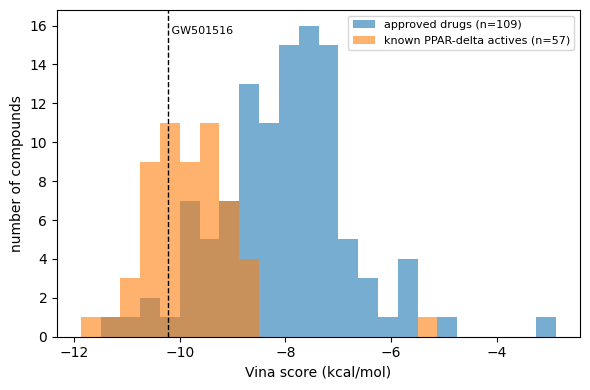

In [34]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
bins = np.linspace(both["vina_score"].min(), both["vina_score"].max(), 25)
ax.hist(both.loc[both["label"] == 0, "vina_score"], bins=bins,
        alpha=0.6, label="approved drugs (n=%d)" % (both["label"] == 0).sum())
ax.hist(both.loc[both["label"] == 1, "vina_score"], bins=bins,
        alpha=0.6, label="known PPAR-delta actives (n=%d)" % both["label"].sum())
ax.axvline(-10.23, linestyle="--", linewidth=1, color="k")
ax.text(-10.23, ax.get_ylim()[1] * 0.95, " GW501516", fontsize=8, va="top")
ax.set_xlabel("Vina score (kcal/mol)")
ax.set_ylabel("number of compounds")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(f"{WORK}/fig_score_distributions.png", dpi=300)
plt.show()

Shows the two score distributions side by side, with the re-docked GW501516
score marked. If docking works, the actives should sit left of the drugs; if
the two piles overlap completely, the AUC near 0.5 will say the same thing.

*** NOT IN COURSE *** None of M01-M11 plots anything, so this code is mine.
Guide section 1 lists Matplotlib as required and section 16 says to label axes
with units and save at 300 dpi, which this does.

PROMPT USED: "In matplotlib, how do I plot two overlapping histograms from a
pandas column split by a 0/1 label, add a vertical reference line, and save it
at 300 dpi?"

In [35]:
mw_of = {r["name"]: r["mw"] for r in LIBRARY}
mw_of.update({r["chembl_id"]: r["mw"] for r in ACTIVES_60})
both["mw"] = both["name"].map(mw_of)

print("mean MW, library :", round(both.loc[both.label == 0, "mw"].mean(), 1))
print("mean MW, actives :", round(both.loc[both.label == 1, "mw"].mean(), 1))
print("missing MW       :", both["mw"].isna().sum())
print()
print("AUC from docking score :", round(auc, 3))
print("AUC from MW alone      :",
      round(roc_auc_score(both["label"], both["mw"]), 3))

mean MW, library : 376.8
mean MW, actives : 478.5
missing MW       : 0

AUC from docking score : 0.892
AUC from MW alone      : 0.84


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Checks whether my AUC is about binding or just about size. Vina scores get
better as molecules get bigger, so if my actives are bigger than my library the
comparison was never fair.

They are: 478 Da against 377 Da. Molecular weight on its own separates the two
sets with AUC 0.840, almost as well as docking's 0.892 - without using the
protein at all.

SOURCE OF THE IDEA: M10 section 3, which shows the same actives and the same
scoring function giving three different answers depending on which decoys you
pick.

*** NOT IN COURSE *** The code is mine. M10 does this on heavy-atom count;
I use molecular weight because profile() already computes it.

PROMPT USED: "I have a pandas table with a 0/1 label and a molecular weight
column. How do I compare the mean weight of each group and compute an ROC AUC
using weight alone as the score?"

In [36]:
for LO, HI in [(350, 600), (400, 550), (400, 600), (450, 550)]:
    m = both[(both["mw"] >= LO) & (both["mw"] <= HI)]
    n_act = int(m["label"].sum())
    n_lib = int((m["label"] == 0).sum())
    if n_act < 5 or n_lib < 5:
        print("MW %d-%d: too few (%d lib, %d act)" % (LO, HI, n_lib, n_act))
        continue
    print("MW %3d-%3d  n=%3d (%3d lib, %2d act)   AUC docking %.3f   AUC MW alone %.3f"
          % (LO, HI, len(m), n_lib, n_act,
             roc_auc_score(m["label"], -m["vina_score"]),
             roc_auc_score(m["label"], m["mw"])))

MW 350-600  n=125 ( 68 lib, 57 act)   AUC docking 0.862   AUC MW alone 0.744
MW 400-550  n= 83 ( 33 lib, 50 act)   AUC docking 0.815   AUC MW alone 0.710
MW 400-600  n= 96 ( 41 lib, 55 act)   AUC docking 0.824   AUC MW alone 0.605
MW 450-550  n= 45 ( 13 lib, 32 act)   AUC docking 0.743   AUC MW alone 0.594


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Re-runs the comparison on compounds of similar size, so size cannot do the work
for docking.

RESULT:

```
MW 350-600   n=125    MW alone 0.744   docking 0.862
MW 400-550   n= 83    MW alone 0.710   docking 0.815
MW 400-600   n= 96    MW alone 0.605   docking 0.824
MW 450-550   n= 45    MW alone 0.594   docking 0.743
```

As the window tightens, size loses almost all its advantage (0.84 down to 0.60)
while docking barely moves (0.89 down to about 0.82). I report the 400-600
window because it has the biggest sample with the size baseline nearest chance.

*** NOT IN COURSE *** The windowing is mine, following M10 section 3's
property-matched decoy idea.

LIMITATION: 0.605 is not 0.5, so some size signal is left, and the sample
shrinks as the window narrows. I only tested molecular weight - cLogP and
heavy-atom count could carry the same problem.

In [38]:
!pip freeze > "{WORK}/requirements.txt"
print("saved")

saved


```
DATA SOURCES

approved_chembl37.sdf
  ChEMBL release 37.
  Filter applied: [WHAT DID YOU SEARCH/FILTER?]
  Downloaded [DATE].  3,311 records.

PPARD_ec50_chembl37.csv
  ChEMBL release 37, target CHEMBL3979 (PPAR-delta).
  Filter applied: [WHAT DID YOU SELECT?]
  Downloaded [DATE].  2,628 rows, of which 2,387 are EC50 in nM.

Structure
  PDB 5U46, downloaded from RCSB in the cell above. Ligand code 7T1.

GW501516
  PubChem CID 9803963, fetched by name in the cell above.

Code and data repository: https://github.com/cjhead0226/as410662-ppard-docking
```

In [ ]:
import os, urllib.request

WORK = "/content/work"
os.makedirs(WORK, exist_ok=True)

REPO = "https://raw.githubusercontent.com/cjhead0226/as410662-ppard-docking/main"
for f in ["approved_chembl37.sdf", "PPARD_ec50_chembl37.csv"]:
    if not os.path.exists(f"{WORK}/{f}"):
        urllib.request.urlretrieve(f"{REPO}/{f}", f"{WORK}/{f}")
        print("downloaded", f)